In [20]:
from google.colab import drive
drive.mount('/content/drive')

!cp -r /content/drive/MyDrive/AssignmentsIPCV/dataset.zip ./
!unzip dataset.zip

ModuleNotFoundError: No module named 'google.colab'

In [2]:
import numpy as np
import cv2
from matplotlib import pyplot as plt

Here we show a sample of scene image

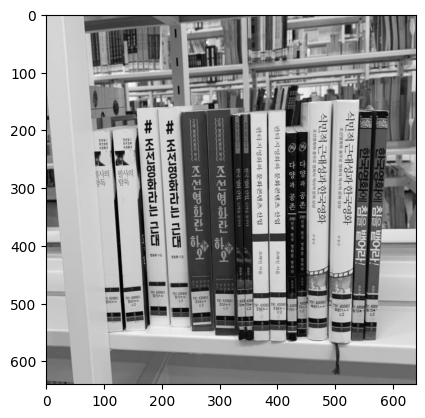

In [3]:
img_scene = cv2.imread("./dataset/scenes/scene_7.jpg", cv2.IMREAD_GRAYSCALE)
plt.imshow(img_scene, cmap="gray", vmin=0, vmax=255)
plt.show()

Here we show a sample of model image

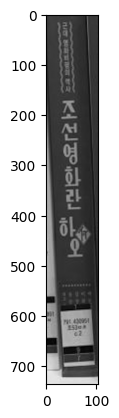

In [4]:
img_model = cv2.imread("./dataset/models/model_20.png", cv2.IMREAD_GRAYSCALE)
plt.imshow(img_model, cmap="gray", vmin=0, vmax=255)
plt.show()

### Keypoint Detection

In [5]:
# Initiate SIFT detector
sift = cv2.SIFT_create()

In [6]:
# find the keypoints and descriptors with SIFT
kp_model = sift.detect(img_model)
print(f"Number of keypoints in model image: {len(kp_model)}")

Number of keypoints in model image: 572


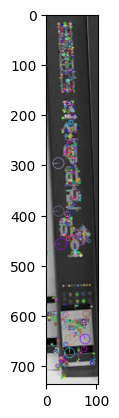

In [7]:
img_visualization = cv2.drawKeypoints(  image=img_model, 
                                        keypoints=kp_model, 
                                        outImage=None, 
                                        flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.imshow(img_visualization)
plt.show()

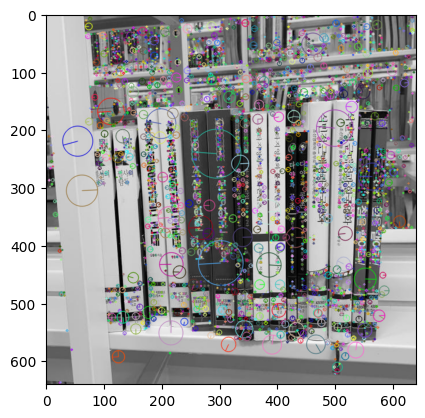

In [8]:
kp_scene = sift.detect(img_scene)
img = cv2.drawKeypoints(img_scene, kp_scene, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.imshow(img)
plt.show()

In [9]:
# Describing keypoints for model and scene images
kp_model, des_model = sift.compute(img_model, kp_model)
kp_scene, des_scene = sift.compute(img_scene, kp_scene)

In [10]:
print("Number of model descriptors: ", len(des_model))
print("Dimensionality of a SIFT descriptor: ", des_model[0].shape)
print("Descriptor type: ", des_model[0].dtype)
print(des_model[0])

Number of model descriptors:  572
Dimensionality of a SIFT descriptor:  (128,)
Descriptor type:  float32
[ 72. 137. 126.  29.   3.   3.   0.   0. 137. 135.   7.   0.   0.   0.
   0.   3.  28.  19.   3.   0.   0.   0.   2.  19.   8.   4.  11.  11.
   1.   0.   6.  24. 137.  88.  10.   7.  28.  62.  38.  51. 137. 112.
   2.   0.   0.   0.   6.  64.  48.  11.   9.  32.  11.   3.  16.  59.
   3.   3.  47. 137.  29.   0.   1.   8.  27.   1.   0.   0.  17.  54.
 137. 128. 137.  62.   9.   1.   3.   5.  43.  93.  25.  44.  40.  38.
   9.   1.   1.   4.   0.   0.   2.  35.  26.   0.   0.   0.   0.   0.
   0.   0.  14.  18.  40.  11.   4.   9.   0.   0.   7.   5.   6.   2.
   1.   5.   1.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.
   0.   0.]


In [11]:
# Defining index for approximate kdtree algorithm
FLANN_INDEX_KDTREE = 1

# Defining parameters for algorithm
index_params = dict(algorithm=FLANN_INDEX_KDTREE, trees=5)

# Defining search params.
# checks=50 specifies the number of times the trees in the index should be recursively traversed.
# Higher values give better precision, but also take more time.
search_params = dict(checks=50)

# Initializing matcher
flann = cv2.FlannBasedMatcher(index_params, search_params)

# Matching and finding the 2 closest elements for each model descriptor
matches = flann.knnMatch(des_model, des_scene, k=2)

In [12]:
good = []
for m, n in matches:
    if m.distance < 0.8 * n.distance:
        good.append(m)

print(f"Number of good matches: {len(good)}")

Number of good matches: 178


In [13]:
# Checking if enough matches are found
MIN_MATCH_COUNT = int(0.2 * len(kp_model))  # 20% of model keypoints

if len(good) > MIN_MATCH_COUNT:
    # Building the correspondence arrays of good matches
    src_pts = np.float32([kp_model[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
    dst_pts = np.float32([kp_scene[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
    # Using RANSAC to estimate a robust homography.
    # It returns the homography M and a mask for the discarded points.
    
    M, mask = cv2.findHomography(srcPoints=src_pts, dstPoints=dst_pts, method=cv2.RANSAC, ransacReprojThreshold=5.0) 
    ##ransacReprojThreshold is the measure in pixels to state that a point is an inlier or an outlier.point in the ransac method

    # Mask of discarded point used in visualization
    matches_mask = mask.ravel().tolist()

    # Corners of the model image
    h, w = img_model.shape
    pts = np.float32([[0,0], [0,h-1], [w-1,h-1], [w-1,0]]).reshape(-1, 1, 2)

    # Projecting the corners into the scene image
    dst = cv2.perspectiveTransform(pts, M)

    # Drawing the bounding box
    img_train_p = cv2.polylines(img_scene,[np.int32(dst)], True, (0, 0, 0), 3, cv2.LINE_AA)

else:
    print(f"Not enough matches are found - {len(good)}/{MIN_MATCH_COUNT}")
    matches_mask = None

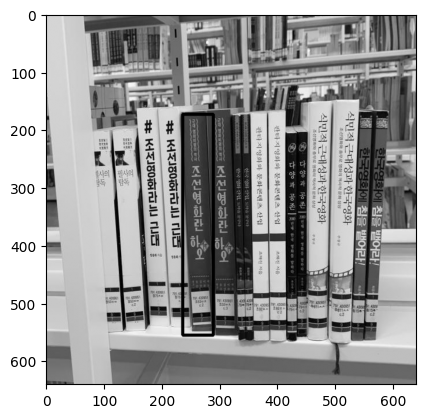

In [14]:
plt.imshow(img_train_p, cmap="gray", vmin=0, vmax=255)
plt.show()

In [45]:
def kp_matching_bf(des_model, des_scene, norm_type=cv2.NORM_L2, lowe_ratio=0.8):
    # Create BFMatcher object
    bf = cv2.BFMatcher(norm_type)

    # Match descriptors (2 nearest neighbors)
    matches = bf.knnMatch(des_model, des_scene, k=2)

    # Apply Lowe's ratio test
    good = []
    for m, n in matches:
        if m.distance < lowe_ratio * n.distance:
            good.append(m)

    return good



# Given an image, detect keypoints and compute descriptors using SIFT
def kp_detection_and_description(image):
    # Initialize SIFT detector
    sift = cv2.SIFT_create()

    # Detect keypoints
    keypoints = sift.detect(image)

    # Compute descriptors
    keypoints, descriptors = sift.compute(image = image, keypoints = keypoints)

    return keypoints, descriptors

# Function to perform keypoint matching using FLANN and return only the good matches
def kp_matching(des_model, des_scene, flann_index, checks=50, trees=5, lowe_ratio=0.8):
    # Define index parameters for FLANN
    index_params = dict(algorithm=flann_index, trees=trees)

    # Define search parameters
    search_params = dict(checks=checks)

    # Initialize FLANN matcher
    flann = cv2.FlannBasedMatcher(index_params, search_params)

    # Match descriptors and find the 2 closest elements for each model descriptor
    matches = flann.knnMatch(des_model, des_scene, k=2)

    # Filter matches using the ratio test
    good = []
    for m, n in matches:
        if m.distance < lowe_ratio * n.distance:
            good.append(m)

    return good


def find_model_in_scene(img_model, img_scene, min_match_count_pct, good_matches, method=cv2.RANSAC, ransacReprojThreshold=5.0):
    # Check if enough matches are found
    MIN_MATCH_COUNT = int(min_match_count_pct * len(img_model))  # Percentage of model keypoints

    if len(good_matches) >= MIN_MATCH_COUNT:
        # Build correspondence arrays of good matches
        src_pts = np.float32([img_model[m.queryIdx].pt for m in good_matches]).reshape(-1, 1, 2)
        dst_pts = np.float32([img_scene[m.trainIdx].pt for m in good_matches]).reshape(-1, 1, 2)

        # Estimate a robust homography using RANSAC
        M, mask = cv2.findHomography(srcPoints=src_pts, dstPoints=dst_pts, method=method, ransacReprojThreshold=ransacReprojThreshold)

        return M, mask
    else:
        print(f"Not enough matches are found - {len(good_matches)}/{MIN_MATCH_COUNT}")
        return None, None

# Function to draw the bounding box around the detected model in the scene
def draw_bounding_box(img_scene, img_model, M):
    # Corners of the model image
    h, w = img_model.shape[:2]
    pts = np.float32([[0,0], [0,h-1], [w-1,h-1], [w-1,0]]).reshape(-1, 1, 2)

    # Project the corners into the scene image
    dst = cv2.perspectiveTransform(pts, M)

    # Draw the bounding box
    img_scene_with_box = cv2.polylines(img_scene, [np.int32(dst)], True, (255, 0, 0), 3, cv2.LINE_AA)

    return np.int32(dst), img_scene_with_box

# Visualize results showing on the left the model image and on the right the scene image with the bounding box
def visualize_results(img_model, img_scene_with_box):
    # Create a figure with two subplots
    fig, ax = plt.subplots(1, 2, figsize=(12, 6))

    if len(img_model.shape) == 3:
        img_model = cv2.cvtColor(img_model, cv2.COLOR_BGR2RGB)

    if len(img_scene_with_box.shape) == 3:
        img_scene_with_box = cv2.cvtColor(img_scene_with_box, cv2.COLOR_BGR2RGB)

    # Show the model image on the left
    ax[0].imshow(img_model, vmin=0, vmax=255, cmap='gray')
    ax[0].set_title("Model Image")
    ax[0].axis('off')

    # Show the scene image with the bounding box on the right
    ax[1].imshow(img_scene_with_box, vmin=0, vmax=255, cmap='gray')
    ax[1].set_title("Scene Image with Bounding Box")
    ax[1].axis('off')

    plt.show()

In [58]:
def main(img_model, img_scene, flann_index=1, checks=50, trees=5, min_match_count_pct=0.2, ransac_reproj_threshold=5.0, method=cv2.RANSAC, lowe_ratio=0.8, visualize=False, results={}, book_idx=None, scene_idx=None):

    idx = f"book_{book_idx}-scene_{scene_idx}" 
    results[idx] = {'detections': 0, 'corners': [], 'area': []}

    # Detect keypoints and compute descriptors for model and scene images
    kp_model, des_model = kp_detection_and_description(img_model)
    kp_scene, des_scene = kp_detection_and_description(img_scene)

    # Perform keypoint matching
    #good_matches = kp_matching(des_model, des_scene, flann_index, checks, trees)
    good_matches = kp_matching_bf(des_model, des_scene, norm_type=cv2.NORM_L2)

    #### detect multiple instances of the model in the scene ####
    drawn_scene = img_scene.copy()
    remaining_matches = good_matches.copy()
    detections = 0

    while True:
       
        M, mask = find_model_in_scene(kp_model, kp_scene, min_match_count_pct, remaining_matches, method, ransac_reproj_threshold)
        
        if M is None:
            break  # Stop if no more valid detections

        # Draw bounding box on the current scene
        corners,drawn_scene = draw_bounding_box(drawn_scene, img_model, M)
        results[idx]['corners'].append(corners)
        results[idx]['area'].append(cv2.contourArea(corners))
        detections += 1

        # Rimuovi i match inliers (già usati)
        mask = mask.ravel().tolist()
        remaining_matches = [m for m, inlier in zip(remaining_matches, mask) if inlier == 0]

        #min_match_count_pct *= (0.6 + ((detections-1)* 0.14)) # Decrease the threshold for the next iteration to find more instances
        min_match_count_pct = max(0.06, min_match_count_pct * (0.6 + ((detections-1)* 0.14)))
        print(min_match_count_pct)
        # Termina se non ci sono abbastanza match per un'altra occorrenza
        if len(remaining_matches) < int(min_match_count_pct * len(kp_model)):
            print(f"Not enough matches left for further detections - {len(remaining_matches)}/{int(min_match_count_pct * len(kp_model))}")
            break

    print(f"Number of detections: {detections}")
    if detections > 0:
        results[idx]['detections'] = detections
        if visualize:
            visualize_results(img_model, drawn_scene)

    else:
        print("No instances of the model were detected in the scene.")
    #### detect multiple instances of the model in the scene ####

    return results

    '''# Find the model in the scene
    M, mask = find_model_in_scene(kp_model, kp_scene, min_match_count_pct, good_matches, method, ransac_reproj_threshold)

    if M is not None:
        # Draw the bounding box around the detected model in the scene
        img_scene_with_box = draw_bounding_box(img_scene, img_model, M)

        # Visualize results
        visualize_results(img_model, img_scene_with_box)'''

In [52]:
# Load images
img_model = cv2.imread("./dataset/models/model_20.png")
img_scene = cv2.imread("./dataset/scenes/scene_7.jpg")

main(img_model, img_scene, min_match_count_pct=0.12, ransac_reproj_threshold=5.0, lowe_ratio=0.75, trees=5, checks=50, book_idx=20, scene_idx=7)

Corners: [[[236 173]]

 [[236 555]]

 [[289 555]]

 [[289 173]]]
0.072
Corners: [[[279 170]]

 [[276 559]]

 [[331 562]]

 [[334 170]]]
0.06
Not enough matches left for further detections - 13/33
Number of detections: 2


{'book_20-scene_7': {'detections': 2,
  'corners': [array([[[279, 170]],
   
          [[276, 559]],
   
          [[331, 562]],
   
          [[334, 170]]], dtype=int32)],
  'area': [0.0]}}

0.06
0.06
Not enough matches left for further detections - 28/34
Number of detections: 2


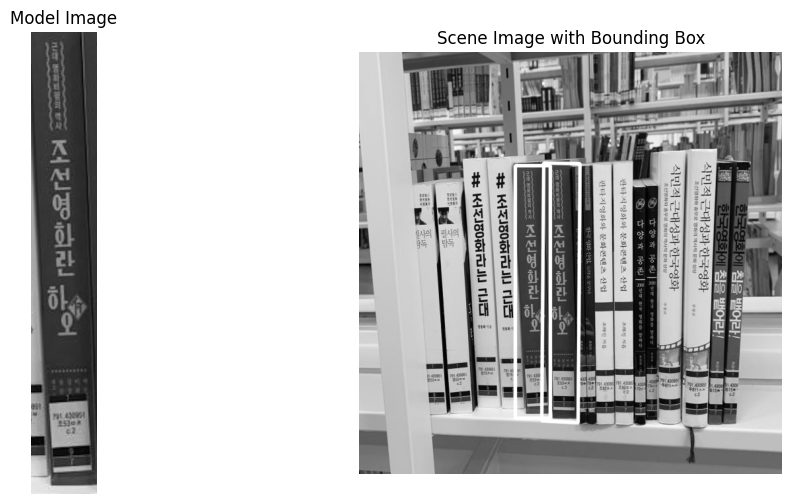

In [ ]:
# Load images
img_model = cv2.imread("./dataset/models/model_20.png", cv2.IMREAD_GRAYSCALE)
img_scene = cv2.imread("./dataset/scenes/scene_7.jpg", cv2.IMREAD_GRAYSCALE)

main(img_model, img_scene, min_match_count_pct=0.05)

Processing model 0...
Not enough matches are found - 23/53
Number of detections: 0
No instances of the model were detected in the scene.
Processing model 1...
Not enough matches are found - 14/53
Number of detections: 0
No instances of the model were detected in the scene.
Processing model 2...
Not enough matches are found - 7/53
Number of detections: 0
No instances of the model were detected in the scene.
Processing model 3...
Not enough matches are found - 19/53
Number of detections: 0
No instances of the model were detected in the scene.
Processing model 4...
Not enough matches are found - 13/53
Number of detections: 0
No instances of the model were detected in the scene.
Processing model 5...
Not enough matches are found - 19/53
Number of detections: 0
No instances of the model were detected in the scene.
Processing model 6...
Not enough matches are found - 18/53
Number of detections: 0
No instances of the model were detected in the scene.
Processing model 7...
Not enough matches a

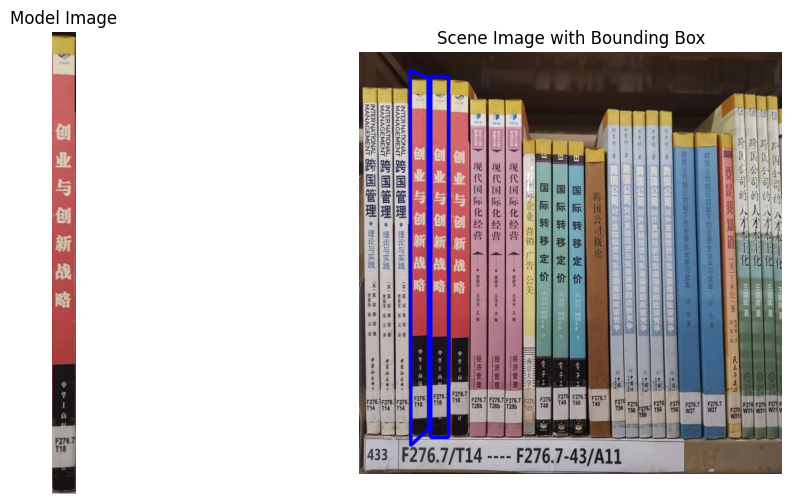

Processing model 19...
Not enough matches are found - 17/53
Number of detections: 0
No instances of the model were detected in the scene.
Processing model 20...
Not enough matches are found - 20/53
Number of detections: 0
No instances of the model were detected in the scene.
Processing model 21...
Not enough matches are found - 9/53
Number of detections: 0
No instances of the model were detected in the scene.
Processing model 22...
Not enough matches are found - 13/53
Number of detections: 0
No instances of the model were detected in the scene.
Processing model 23...
Not enough matches are found - 17/53
Number of detections: 0
No instances of the model were detected in the scene.
Processing model 24...
Not enough matches are found - 31/53
Number of detections: 0
No instances of the model were detected in the scene.
Processing model 25...
Not enough matches are found - 24/53
Number of detections: 0
No instances of the model were detected in the scene.
Processing model 26...
Not enough m

In [34]:
for i in range(0,29):
    img_model = cv2.imread(f"./dataset/models/model_10.png")
    img_scene = cv2.imread(f"./dataset/scenes/scene_{i}.jpg")
    print(f"Processing model {i}...")
    main(img_model, img_scene, min_match_count_pct=0.115, ransac_reproj_threshold=5.0, lowe_ratio=0.75, trees=5, checks=50)

Processing model 0...
Not enough matches are found - 12/54
Number of detections: 0
No instances of the model were detected in the scene.
Processing model 1...
Not enough matches are found - 24/54
Number of detections: 0
No instances of the model were detected in the scene.
Processing model 2...
Not enough matches are found - 28/54
Number of detections: 0
No instances of the model were detected in the scene.
Processing model 3...
Not enough matches are found - 20/54
Number of detections: 0
No instances of the model were detected in the scene.
Processing model 4...
Not enough matches are found - 21/54
Number of detections: 0
No instances of the model were detected in the scene.
Processing model 5...
Not enough matches are found - 25/54
Number of detections: 0
No instances of the model were detected in the scene.
Processing model 6...
Not enough matches are found - 17/54
Number of detections: 0
No instances of the model were detected in the scene.
Processing model 7...
Not enough matches 

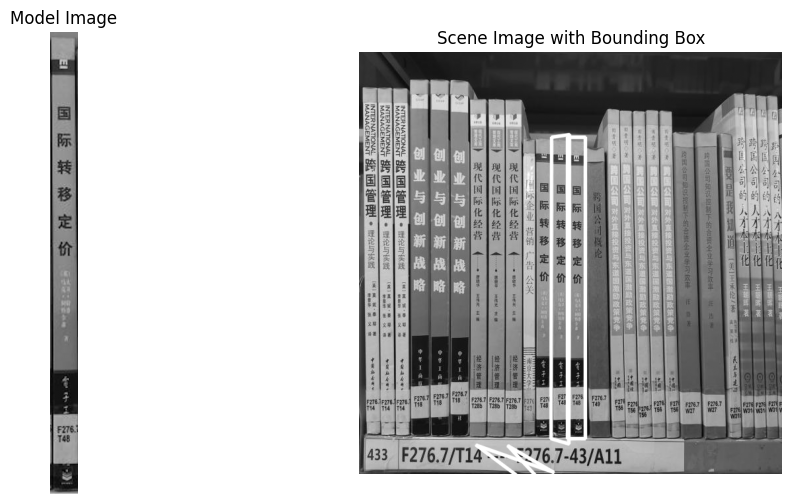

Processing model 19...
Not enough matches are found - 37/54
Number of detections: 0
No instances of the model were detected in the scene.
Processing model 20...
Not enough matches are found - 17/54
Number of detections: 0
No instances of the model were detected in the scene.
Processing model 21...
Not enough matches are found - 20/54
Number of detections: 0
No instances of the model were detected in the scene.
Processing model 22...
Not enough matches are found - 24/54
Number of detections: 0
No instances of the model were detected in the scene.
Processing model 23...
Not enough matches are found - 25/54
Number of detections: 0
No instances of the model were detected in the scene.
Processing model 24...
Not enough matches are found - 22/54
Number of detections: 0
No instances of the model were detected in the scene.
Processing model 25...
Not enough matches are found - 18/54
Number of detections: 0
No instances of the model were detected in the scene.
Processing model 26...
Not enough 

In [24]:
for i in range(0,29):
    img_model = cv2.imread(f"./dataset/models/model_9.png", cv2.IMREAD_GRAYSCALE)
    img_scene = cv2.imread(f"./dataset/scenes/scene_{i}.jpg", cv2.IMREAD_GRAYSCALE)
    print(f"Processing model {i}...")
    main(img_model, img_scene, min_match_count_pct=0.12, ransac_reproj_threshold=5.0, lowe_ratio=0.75, trees=5, checks=50)

```
Book 0 - 2 instance(s) found:
  Instance 1 {top_left: (100,200), top_right: (110, 220), bottom_left: (10, 202), bottom_right: (10, 208), area: 230px}
  Instance 2 {top_left: (90,310), top_right: (95, 340), bottom_left: (24, 205), bottom_right: (23, 234), area: 205px}
Book 1 – 1 instance(s) found:
.
.
.
```

In [59]:
results = {}

for i in range(0, 29):
   print(f"------------------------------ Processing scene {i} ------------------------------")
   for j in range(0, 22):
      img_model = cv2.imread(f"./dataset/models/model_{j}.png")
      img_scene = cv2.imread(f"./dataset/scenes/scene_{i}.jpg")
      results = main(img_model, 
                     img_scene, 
                     min_match_count_pct=0.12, 
                     ransac_reproj_threshold=5.0, 
                     lowe_ratio=0.75, 
                     trees=5, 
                     checks=50, 
                     results=results, 
                     book_idx=j, 
                     scene_idx=i)
      
      detections = results[f"book_{j}-scene_{i}"]['detections']
      if detections > 0:
         print(f"Book {j} - {detections} instance(s) found:")
         for k in range(detections):
            corners = results[f"book_{j}-scene_{i}"]['corners'][k]
            
            area = results[f"book_{j}-scene_{i}"]['area'][k]

            top_left     = tuple(map(int, corners[0].ravel()))
            top_right    = tuple(map(int, corners[3].ravel()))
            bottom_left  = tuple(map(int, corners[1].ravel()))
            bottom_right = tuple(map(int, corners[2].ravel()))

            print(f"\t Instance {k+1}: {{top-left: {top_left}, top-right: {top_right}, bottom-left: {bottom_left}, bottom-right: {bottom_right}, area: {int(area)}px}}")
      else:
         print(f"Book {j} - {detections} instance(s) found")



------------------------------ Processing scene 0 ------------------------------
Not enough matches are found - 8/47
Number of detections: 0
No instances of the model were detected in the scene.
Book 0 - 0 instance(s) found
Not enough matches are found - 7/41
Number of detections: 0
No instances of the model were detected in the scene.
Book 1 - 0 instance(s) found
Not enough matches are found - 9/53
Number of detections: 0
No instances of the model were detected in the scene.
Book 2 - 0 instance(s) found
Not enough matches are found - 17/86
Number of detections: 0
No instances of the model were detected in the scene.
Book 3 - 0 instance(s) found
Not enough matches are found - 33/156
Number of detections: 0
No instances of the model were detected in the scene.
Book 4 - 0 instance(s) found
Not enough matches are found - 31/147
Number of detections: 0
No instances of the model were detected in the scene.
Book 5 - 0 instance(s) found
Not enough matches are found - 10/48
Number of detection

KeyboardInterrupt: 

Exercise 1 - Number of instances;

Exercise 2 - Dimension of each instance (area in pixel of the bounding box that encloses each one of them);

Exercise 3 - Position in the image reference system of each instance (four corners of the bounding box that enclose them);

Exercise 4 - Overlay of the bounding boxes on the scene images.